# Train notebook

In [1]:
import random
import shutil
import sys
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import trackio
from IPython.display import Image as IPImage, display
from PIL import Image, ImageDraw
from ultralytics import YOLO

ROOT = Path.cwd()
assert (ROOT / "split_dataset.py").exists(), f"run the notebook from the task folder, not {ROOT}"
sys.path.insert(0, str(ROOT))

from merge_datasets import MERGED_DIR, merge_split
from split_dataset import split_task

# Dataset preparation

In [3]:
# Val = a contiguous block of frames per clip, with GAP frame numbers dropped on both sides of it.
# Clips not in val_splits treated as train. Images without a label file are kept as background.

RAW_DIR = ROOT / "raw_data"
TASKS = ["task_5", "task_6", "task_7", "task_8"]
VAL_SPLITS = {
    # [File_name]: [start_frame], [end_frame], [gap_frames_number]
    "task_6": ([(0, 99)], 100),
    "task_7": ([(0, 34)], 30),
}

split_dirs = []
for task in TASKS:
    val_ranges, gap = VAL_SPLITS.get(task, ([], 0))
    split_dirs.append(split_task(RAW_DIR / task, val_ranges, gap))
print("\n===========\n")
for split in ("train", "val"):
    data_yaml = merge_split(split, split_dirs)
print("\n===========\n")
print(data_yaml.read_text())

task_5: 367 images, val ranges none, gap 0
  train:  367 images, frames 0..732
  gap  :    0 images, frames - (dropped)
  val  :    0 images, frames -
  -> D:\Computer Vision\Computer-Vision-Test-Task\raw_data\splits\task_5
task_6: 375 images, val ranges [(0, 99)], gap 100
  train:  275 images, frames 200..748
  gap  :   50 images, frames 100..198 (dropped)
  val  :   50 images, frames 0..98
  -> D:\Computer Vision\Computer-Vision-Test-Task\raw_data\splits\task_6
task_7: 203 images, val ranges [(0, 34)], gap 30
  train:  170 images, frames 66..404
  gap  :   15 images, frames 36..64 (dropped)
  val  :   18 images, frames 0..34
  background (no label file, written empty): frame_000402, frame_000404
  -> D:\Computer Vision\Computer-Vision-Test-Task\raw_data\splits\task_7
task_8: 76 images, val ranges none, gap 0
  train:   76 images, frames 0..300
  gap  :    0 images, frames - (dropped)
  val  :    0 images, frames -
  -> D:\Computer Vision\Computer-Vision-Test-Task\raw_data\splits\task

# Data analysis

train: 888 images (2 background), 10507 boxes
       box size (sqrt area, px): min 5, median 27, max 315
       boxes < 32 px: 5793 (55%)
val  : 68 images (0 background), 244 boxes
       box size (sqrt area, px): min 7, median 20, max 399
       boxes < 32 px: 125 (51%)


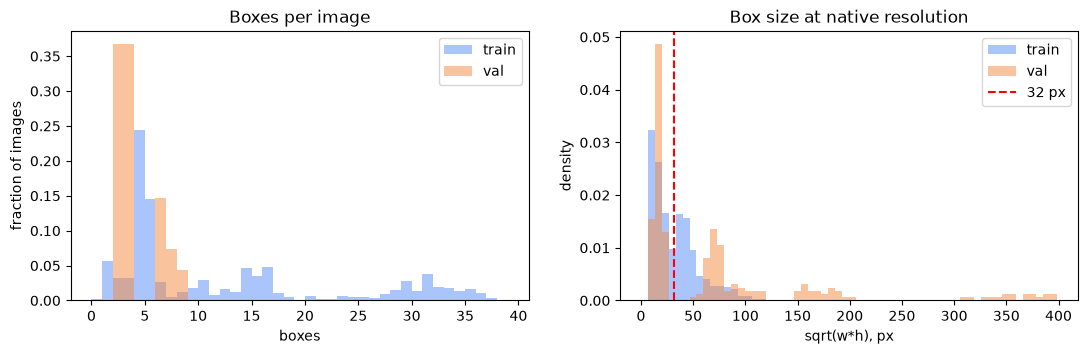

In [3]:
def label_for(img_path):
    """<ds>/images/<split>/x.png -> <ds>/labels/<split>/x.txt"""
    return img_path.parents[2] / "labels" / img_path.parent.name / f"{img_path.stem}.txt"


def read_boxes(label_path):
    """class cx cy w h (normalized) rows. Missing or empty label file = background image, 0 boxes."""
    if not label_path.exists() or label_path.stat().st_size == 0:
        return np.zeros((0, 5))
    return np.loadtxt(label_path, ndmin=2)


def split_stats(split):
    """Boxes per image and sqrt(area) of every box, in pixels, for one split of the merged dataset."""
    frames = sorted((MERGED_DIR / "images" / split).glob("*.png"))
    assert frames, f"no images in {MERGED_DIR / 'images' / split}: run Dataset preparation first"
    per_image, sides = [], []
    for img in frames:
        W, H = Image.open(img).size
        rows = read_boxes(label_for(img))
        per_image.append(len(rows))
        sides.append(np.sqrt(rows[:, 3] * W * rows[:, 4] * H))  # sqrt(area): one "object size" number per box
    return np.array(per_image), np.concatenate(sides)


# The merged dataset (output of Dataset preparation) is assumed to exist.
stats = {split: split_stats(split) for split in ("train", "val")}
for split, (per_image, side) in stats.items():
    print(f"{split:5}: {len(per_image)} images ({(per_image == 0).sum()} background), {len(side)} boxes")
    print(f"       box size (sqrt area, px): min {side.min():.0f}, median {np.median(side):.0f}, max {side.max():.0f}")
    print(f"       boxes < 32 px: {(side < 32).sum()} ({(side < 32).mean():.0%})")  # :cry

# density=True: val is ~10x smaller than train, so compare shapes, not counts
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
max_boxes = max(per_image.max() for per_image, _ in stats.values())
size_bins = np.linspace(0, max(side.max() for _, side in stats.values()), 61)
for split, (per_image, side) in stats.items():
    axes[0].hist(per_image, bins=range(0, max_boxes + 2), density=True, alpha=0.5, label=split)
    axes[1].hist(side, bins=size_bins, density=True, alpha=0.5, label=split)
axes[0].set(title="Boxes per image", xlabel="boxes", ylabel="fraction of images")
axes[0].legend()
axes[1].axvline(32, color="red", ls="--", label="32 px")
axes[1].set(title="Box size at native resolution", xlabel="sqrt(w*h), px", ylabel="density")
axes[1].legend()
plt.show()

## Sanity checks

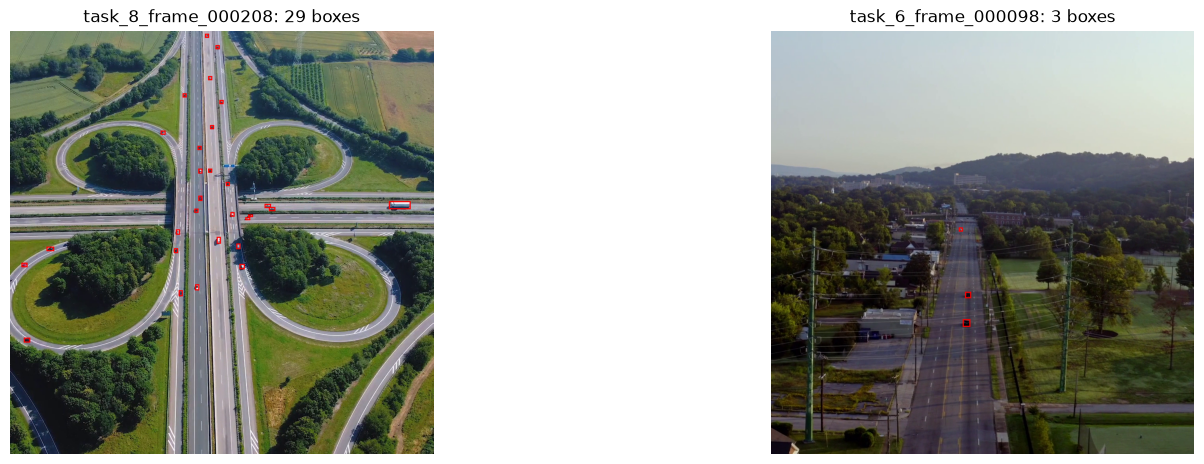

In [4]:
SEED = 0 # Change to see different images

def draw_gt(img_path, ax):
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    draw = ImageDraw.Draw(im)
    rows = read_boxes(label_for(img_path))
    for _, cx, cy, w, h in rows:
        draw.rectangle([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H],
                       outline=(255, 0, 0), width=3)
    ax.imshow(im)
    ax.set_title(f"{img_path.stem}: {len(rows)} boxes")
    ax.axis("off")

train_frames = sorted((MERGED_DIR / "images" / "train").glob("*.png"))
val_frames = sorted((MERGED_DIR / "images" / "val").glob("*.png"))
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
rng = random.Random(SEED)
draw_gt(rng.choice(train_frames), axes[0])
draw_gt(rng.choice(val_frames), axes[1])
plt.show()

# Training loop

In [4]:
# (for future), any custom collate_fn will require separate .py file in order to work on Windows

RUNS_DIR = ROOT / "output" / "runs"
WEIGHTS_DIR = ROOT / "weights"
TRACKIO_PROJECT = "The-Fourth-Law-test-task"

@dataclass
class TrainConfig:
    model: str = "yolo26-shufflenet.yaml"  # .yaml = build from scratch (ImageNet backbone), .pt = load a checkpoint from weights/
    imgsz: int = 640 # 1080 -> 640 (without letterboxing)
    epochs: int = 50
    patience: int = 20
    batch: int = 16
    seed: int = 0
    workers: int = 4
    cache: bool | str = False
    name: str = "yolo26_shufflenet_640"


# region TrackIo integration
def _plain(value):
    """trackio config must be JSON-serializable (trainer.args holds Paths etc.)."""
    return value if isinstance(value, (int, float, str, bool, type(None))) else str(value)


def make_trackio_callbacks(cfg: TrainConfig) -> dict:
    """Callback to hook Ultralytics into trackio."""

    state = {"trained_epoch": False, "last_step": 0}
    def on_pretrain_routine_start(trainer):
        config = {k: _plain(v) for k, v in vars(trainer.args).items()}
        config.update({f"cfg/{k}": v for k, v in asdict(cfg).items()})
        trackio.init(project=TRACKIO_PROJECT, name=Path(trainer.save_dir).name, config=config, embed=False)

    def on_train_epoch_end(trainer):
        state["trained_epoch"] = True

    def on_fit_epoch_end(trainer):
        if not state["trained_epoch"]:
            return
        state["trained_epoch"] = False
        state["last_step"] = trainer.epoch + 1
        # trainer.metrics: val losses + precision/recall/mAP50/mAP50-95 for this epoch
        trackio.log(
            {
                **trainer.label_loss_items(trainer.tloss, prefix="train"),
                **trainer.metrics,
                **trainer.lr,
                "epoch": trainer.epoch + 1,
            },
            step=trainer.epoch + 1,
        )

    def on_train_end(trainer):
        best = {f"best/{k}": v for k, v in trainer.metrics.items() if k.startswith("metrics/")}
        trackio.log(best, step=state["last_step"])
        trackio.finish()

    return {
        "on_pretrain_routine_start": on_pretrain_routine_start,
        "on_train_epoch_end": on_train_epoch_end,
        "on_fit_epoch_end": on_fit_epoch_end,
        "on_train_end": on_train_end,
    }
# endregion


def train(cfg: TrainConfig, data_yaml: Path) -> Path:
    WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
    model_path = ROOT / cfg.model if cfg.model.endswith(".yaml") else WEIGHTS_DIR / cfg.model
    model = YOLO(model_path)
    n_params = sum(p.numel() for p in model.model.parameters())
    print(f"{model_path.name}: {n_params:,} parameters")

    for event, fn in make_trackio_callbacks(cfg).items():
        model.add_callback(event, fn)

    model.train(
        data=str(data_yaml),
        imgsz=cfg.imgsz,
        epochs=cfg.epochs,
        patience=cfg.patience,
        batch=cfg.batch,
        seed=cfg.seed,
        deterministic=True,
        workers=cfg.workers,
        cache=cfg.cache,
        project=str(RUNS_DIR),
        name=cfg.name,
    )

    # Copy best weights into weights/ dir
    save_dir = Path(model.trainer.save_dir)
    best = save_dir / "weights" / "best.pt"
    if best.exists():
        dst = WEIGHTS_DIR / f"{save_dir.name}_best.pt"
        shutil.copy2(best, dst)
        print(f"best weights -> {dst}")
    return save_dir


cfg = TrainConfig(
    model="yolo26-shufflenet.yaml",
    imgsz=640,
    epochs=50,
    patience=20,
    batch=16,
    seed=42,
    name="yolo26_shufflenet_640",
)
run_dir = train(cfg, data_yaml)

WARNING no model scale passed. Assuming scale='t'.
yolo26-shufflenet.yaml: 408,638 parameters
Ultralytics 8.4.175  Python-3.14.4 torch-2.14.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Computer Vision\Computer-Vision-Test-Task\input\train\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

# Metrics

In [5]:
trackio.show(project=TRACKIO_PROJECT)

In [6]:
# Re-validate best.pt on the val split. To inspect an older run, set run_dir = RUNS_DIR / "<run name>".
best_pt = run_dir / "weights" / "best.pt"
metrics = YOLO(best_pt).val(
    data=str(data_yaml), split="val", imgsz=cfg.imgsz, project=str(RUNS_DIR), name=f"{run_dir.name}_val"
)
print(f"precision: {metrics.box.mp:.3f}")
print(f"recall:    {metrics.box.mr:.3f}")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"mAP50-95:  {metrics.box.map:.3f}")

Ultralytics 8.4.175  Python-3.14.4 torch-2.14.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)
YOLO26-shufflenet summary (fused): 240 layers, 364,959 parameters, 0 gradients, 1.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 3000.1299.5 MB/s, size: 1376.5 KB)
val: Scanning D:\Computer Vision\Computer-Vision-Test-Task\input\train\labels\val.cache... 68 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 68/68 40.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.5it/s 2.0s0.2ss
                   all         68        244      0.921      0.765      0.809      0.532
Speed: 1.2ms preprocess, 3.8ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to D:\Computer Vision\Computer-Vision-Test-Task\output\runs\yolo26_shufflenet_640-2_val
precision: 0.921
recall:    0.765
mAP50:     0.809
mAP50-95:  0.532


results.png


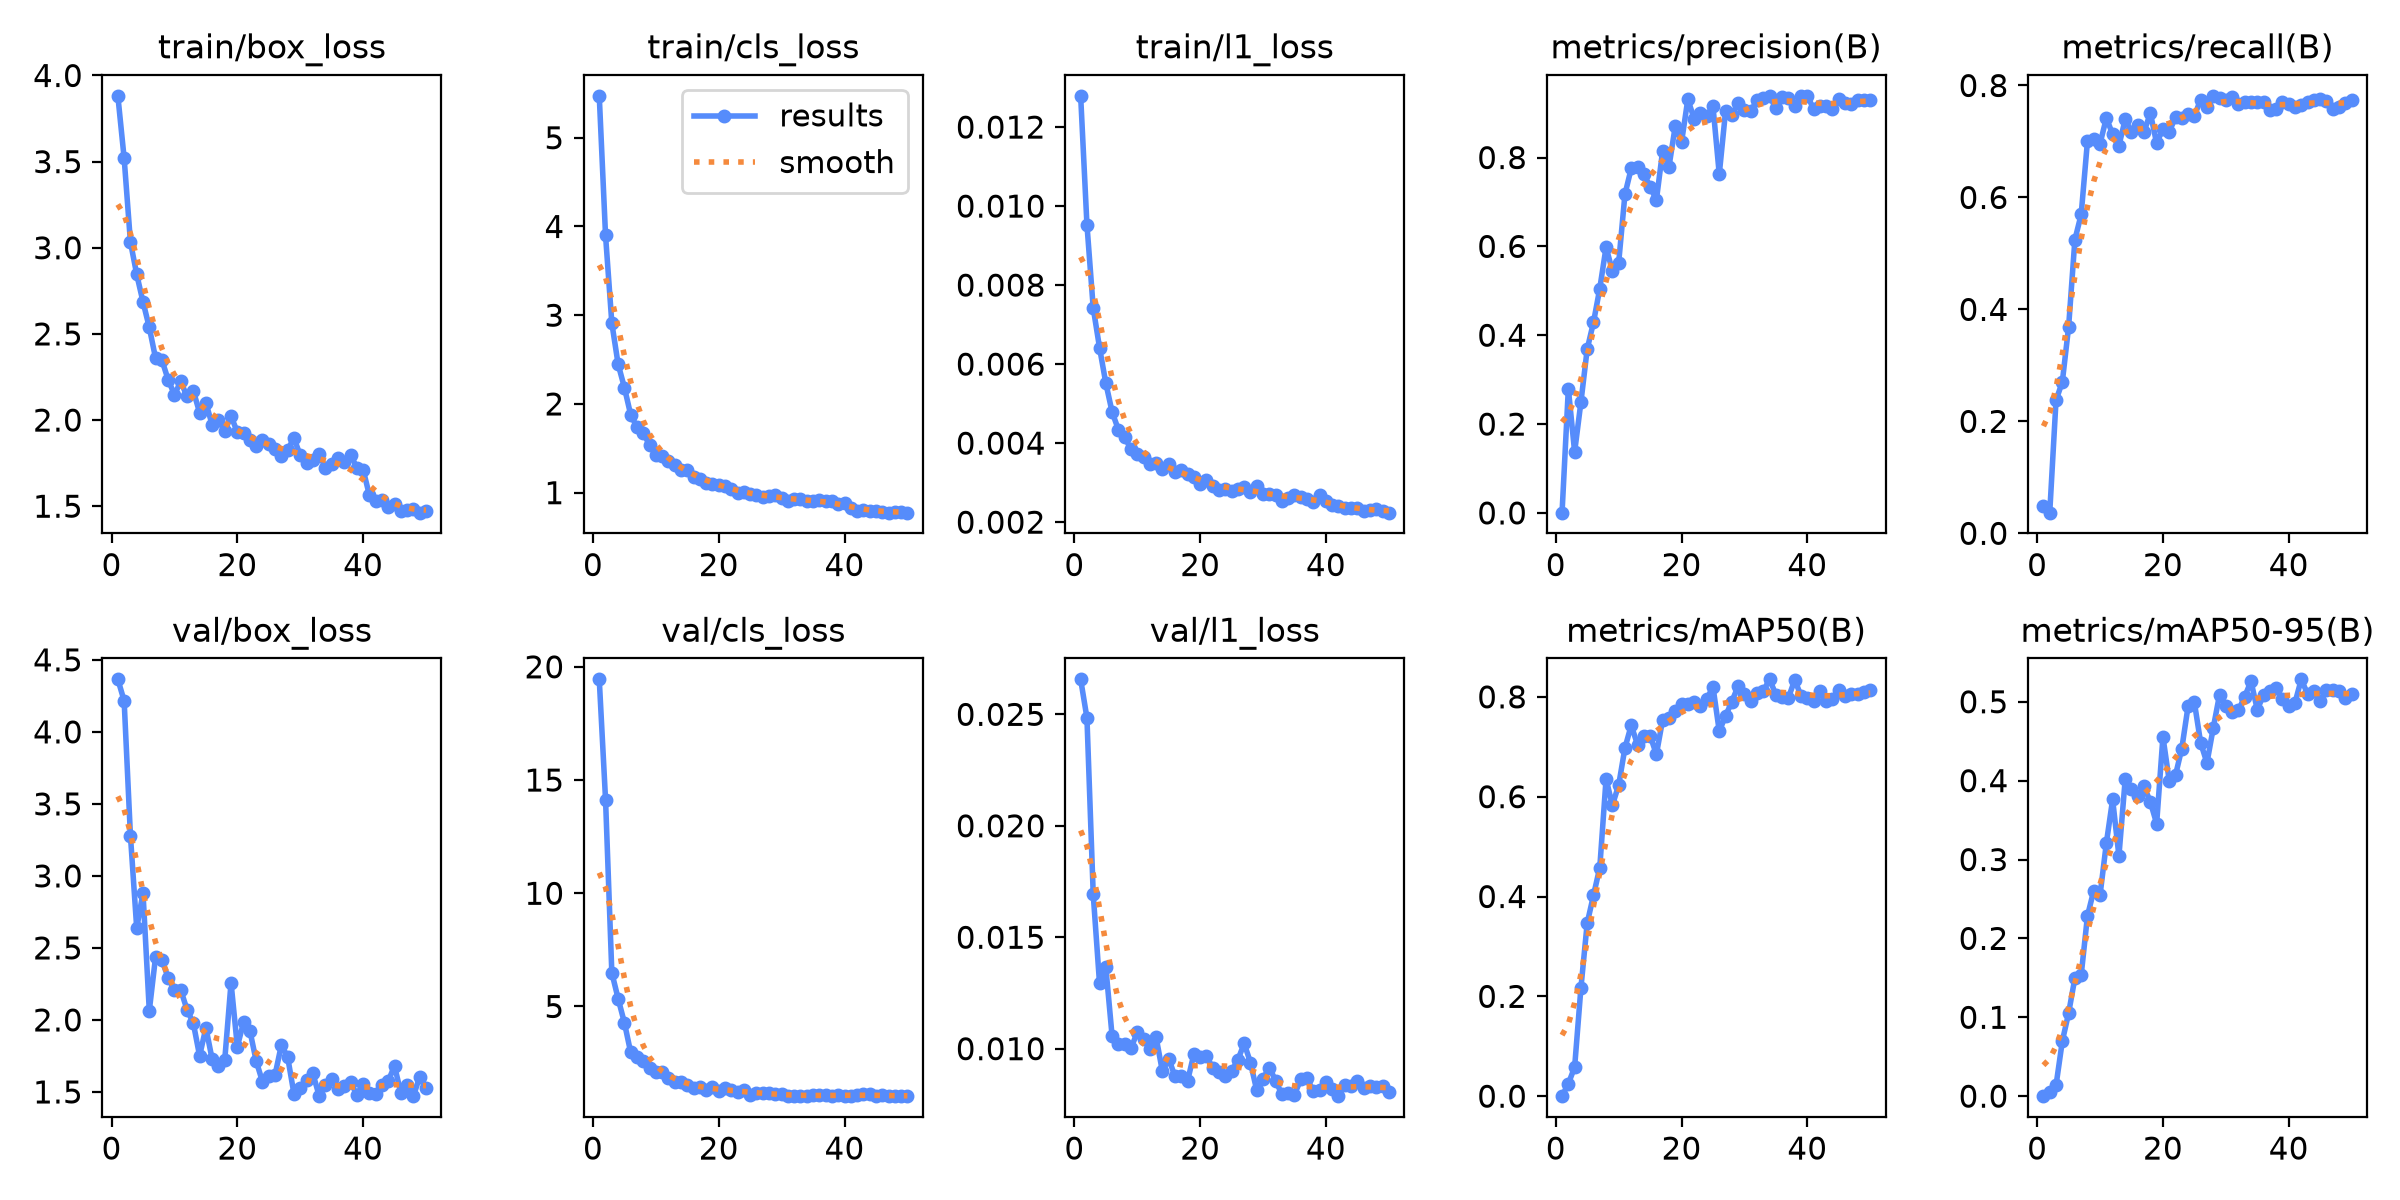

BoxPR_curve.png


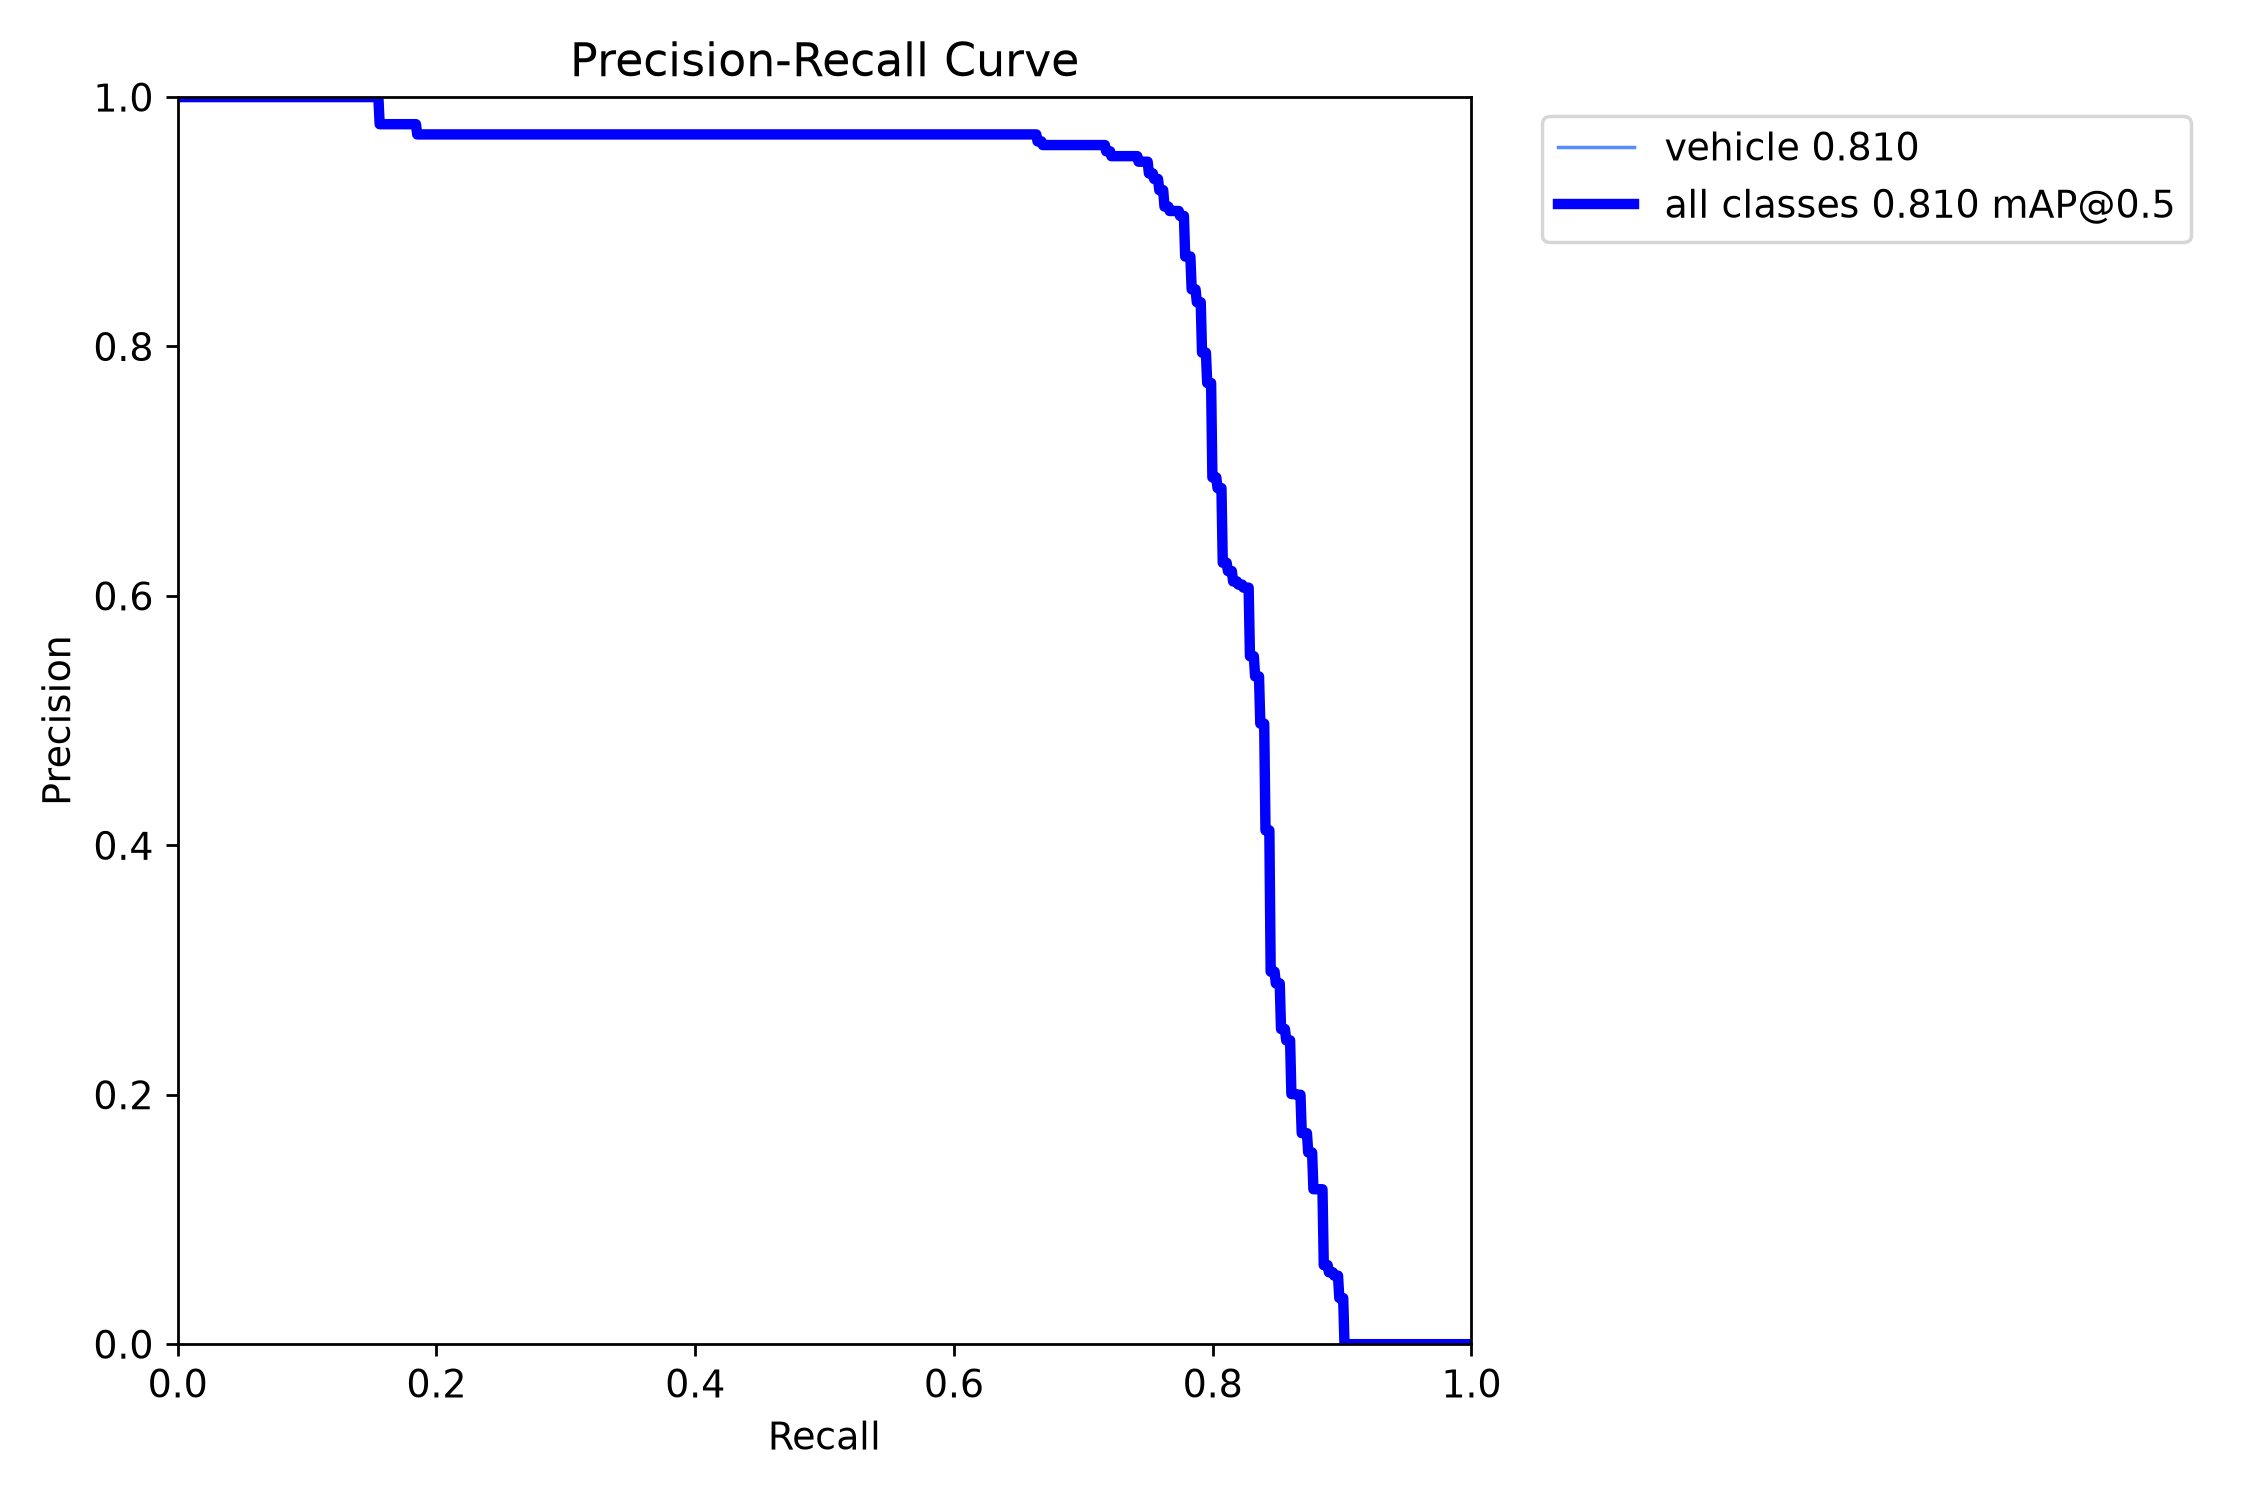

In [7]:
# omitted (add if needed): "confusion_matrix.png", "val_batch0_labels.jpg", "val_batch0_pred.jpg"
for name in ["results.png", "BoxPR_curve.png" ]:
    print(name)
    display(IPImage(filename=str(run_dir / name), width=1000))